In [5]:
!pip install -q -U kaggle
!pip install -q "pillow<13"

import os, random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

In [6]:
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!kaggle datasets download -d divg07/casia-20-image-tampering-detection-dataset -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/divg07/casia-20-image-tampering-detection-dataset
License(s): unknown
100% 2.56G/2.56G [02:21<00:00, 19.3MB/s]



In [7]:
AUTH_DIR = "/content/data/CASIA2/Au"
TAMP_DIR = "/content/data/CASIA2/Tp"

IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def collect(folder):
    return [os.path.join(folder, f) for f in os.listdir(folder)
            if f.lower().endswith(IMG_EXTS)]

auth = collect(AUTH_DIR)
tamp = collect(TAMP_DIR)
print("Authentic:", len(auth), "| Tampered:", len(tamp))

paths  = auth + tamp
labels = [0]*len(auth) + [1]*len(tamp)   # 0 = authentic, 1 = forged

Authentic: 7491 | Tampered: 5123


In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Train:", len(X_train), "| Val:", len(X_val), "| Test:", len(X_test))

Train: 8829 | Val: 1892 | Test: 1893


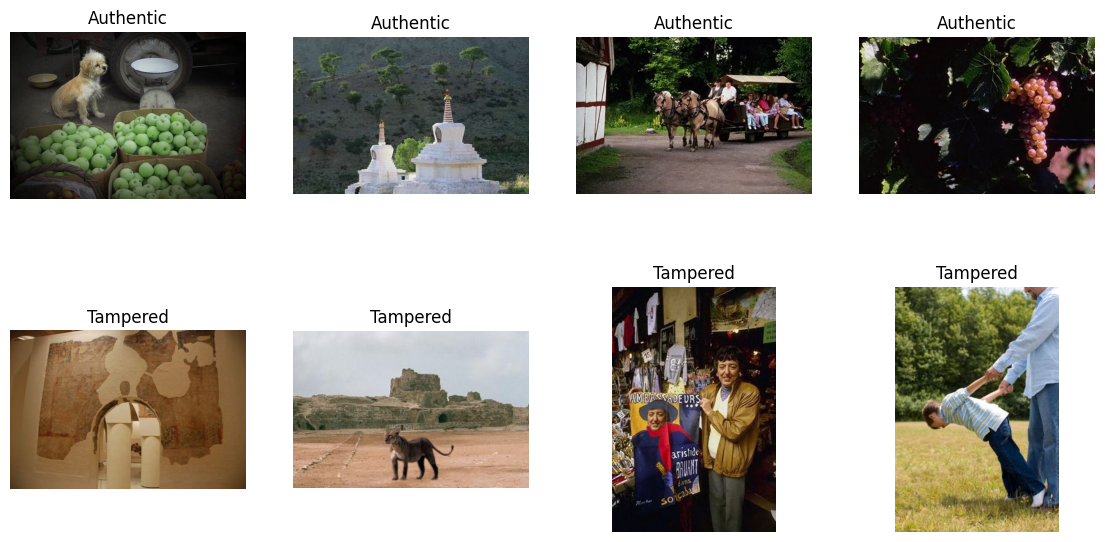

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    a = Image.open(random.choice(auth)).convert("RGB")
    t = Image.open(random.choice(tamp)).convert("RGB")
    axes[0, i].imshow(a); axes[0, i].set_title("Authentic"); axes[0, i].axis("off")
    axes[1, i].imshow(t); axes[1, i].set_title("Tampered"); axes[1, i].axis("off")
plt.show()

# **Detector 1 is splicing**

In [10]:
import io

def ela(path, quality=90, scale=15, size=128):
    img = Image.open(path).convert("RGB")
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=quality)
    buf.seek(0)
    resaved = Image.open(buf).convert("RGB")
    diff = np.abs(np.asarray(img, dtype=np.int16) - np.asarray(resaved, dtype=np.int16))
    diff = np.clip(diff * scale, 0, 255).astype(np.uint8)
    return cv2.resize(diff, (size, size))

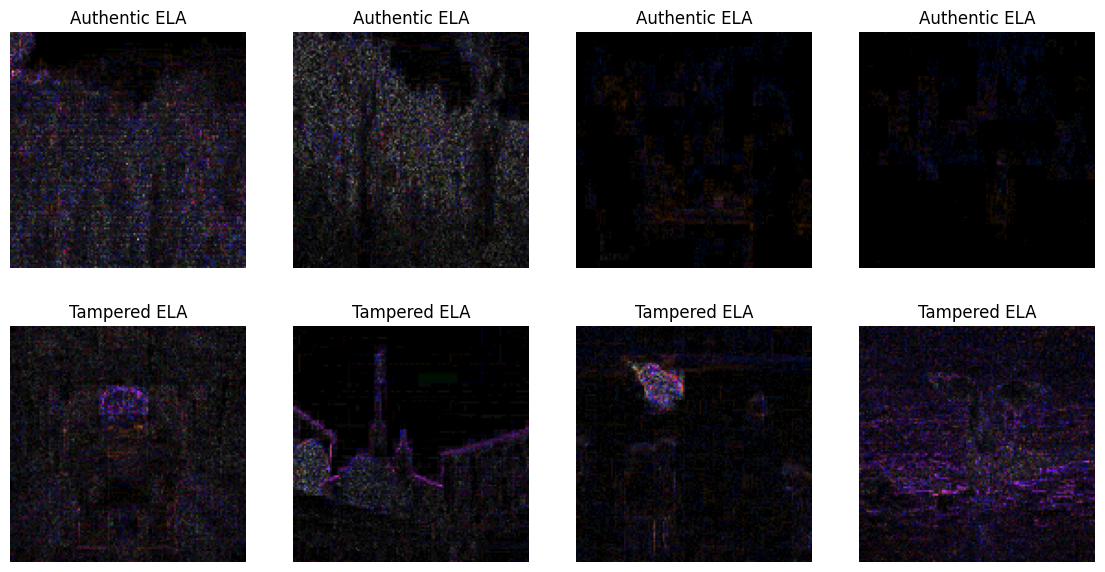

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    a, t = random.choice(auth), random.choice(tamp)
    axes[0, i].imshow(ela(a)); axes[0, i].set_title("Authentic ELA"); axes[0, i].axis("off")
    axes[1, i].imshow(ela(t)); axes[1, i].set_title("Tampered ELA"); axes[1, i].axis("off")
plt.show()

In [12]:
from tqdm import tqdm

def build(paths):
    return np.array([ela(p) for p in tqdm(paths)], dtype=np.uint8)

Xtr = build(X_train); Xva = build(X_val); Xte = build(X_test)
ytr, yva, yte = map(np.array, (y_train, y_val, y_test))
print(Xtr.shape, Xva.shape, Xte.shape)

100%|██████████| 1893/1893 [00:08<00:00, 227.91it/s]


(8829, 128, 128, 3) (1892, 128, 128, 3) (1893, 128, 128, 3)


In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input((128, 128, 3)),
    layers.Rescaling(1/255),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
                    epochs=10, batch_size=32)

Epoch 1/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - accuracy: 0.7876 - loss: 0.4632 - val_accuracy: 0.8425 - val_loss: 0.3789
Epoch 2/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8374 - loss: 0.3807 - val_accuracy: 0.8520 - val_loss: 0.3427
Epoch 3/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8683 - loss: 0.3145 - val_accuracy: 0.8821 - val_loss: 0.2946
Epoch 4/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.8845 - loss: 0.2667 - val_accuracy: 0.8932 - val_loss: 0.2603
Epoch 5/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8958 - loss: 0.2406 - val_accuracy: 0.8885 - val_loss: 0.2816
Epoch 6/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9084 - loss: 0.2096 - val_accuracy: 0.8853 - val_loss: 0.2713
Epoch 7/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9157 - loss: 0.1877 - val_accuracy: 0.8700 - val_loss: 0.3100
Epoch 8/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9240 - loss: 0.1687 - val_acc

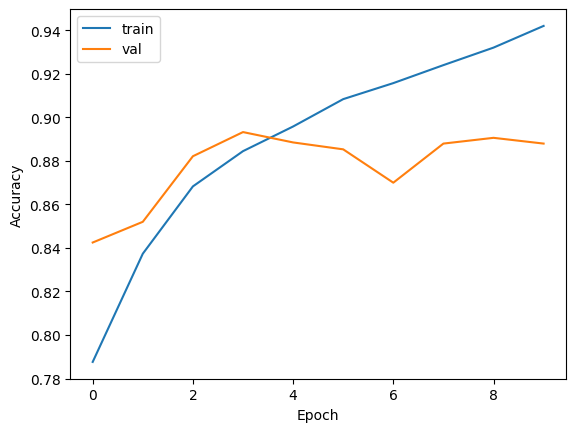

In [14]:
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.show()

60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
              precision    recall  f1-score   support

   Authentic       0.93      0.90      0.91      1124
      Forged       0.86      0.91      0.88       769

    accuracy                           0.90      1893
   macro avg       0.89      0.90      0.90      1893
weighted avg       0.90      0.90      0.90      1893



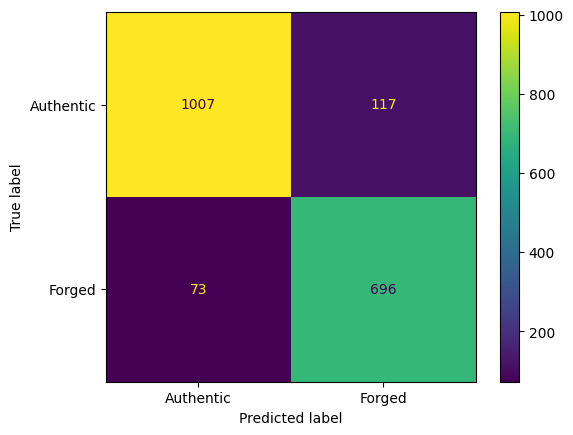

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pred = (model.predict(Xte) > 0.5).astype(int).ravel()
print(classification_report(yte, pred, target_names=["Authentic", "Forged"]))
ConfusionMatrixDisplay(confusion_matrix(yte, pred),
                       display_labels=["Authentic", "Forged"]).plot()
plt.show()

In [16]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/forgery
model.save("/content/drive/MyDrive/forgery/splicing_model.keras")

Mounted at /content/drive


## **Detector 2 is copy-move detection**

In [17]:
def copy_move_score(path, min_dist=40, ratio=0.7, max_side=800):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    s = max_side / max(h, w)
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s)

    sift = cv2.SIFT_create(nfeatures=3000)
    kp, des = sift.detectAndCompute(img, None)
    if des is None or len(kp) < 10:
        return 0, []

    # match the image's descriptors against themselves
    bf = cv2.BFMatcher(cv2.NORM_L2)
    knn = bf.knnMatch(des, des, k=4)

    pairs = []
    for m in knn:
        m = [x for x in m if x.trainIdx != x.queryIdx]   # drop self-match
        if len(m) < 2:
            continue
        if m[0].distance < ratio * m[1].distance:         # ratio test
            p1 = np.array(kp[m[0].queryIdx].pt)
            p2 = np.array(kp[m[0].trainIdx].pt)
            if np.linalg.norm(p1 - p2) > min_dist:        # ignore nearby matches
                pairs.append((p1, p2))

    if len(pairs) < 4:
        return 0, []

    # keep only matches that agree on one consistent copy transformation
    src = np.float32([p[0] for p in pairs])
    dst = np.float32([p[1] for p in pairs])
    M, inl = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC,
                                         ransacReprojThreshold=3)
    if inl is None:
        return 0, []
    good = [p for p, k in zip(pairs, inl.ravel()) if k]
    return len(good), good

Copy-move images found: 3274


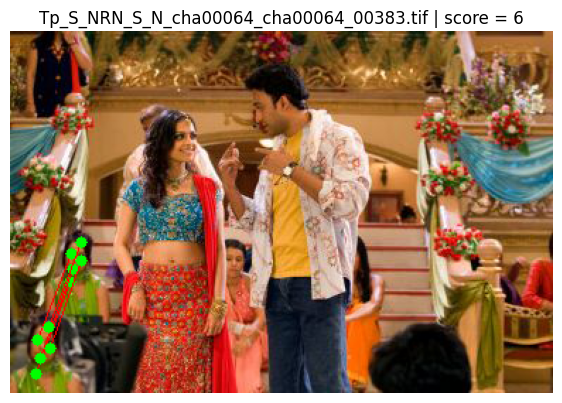

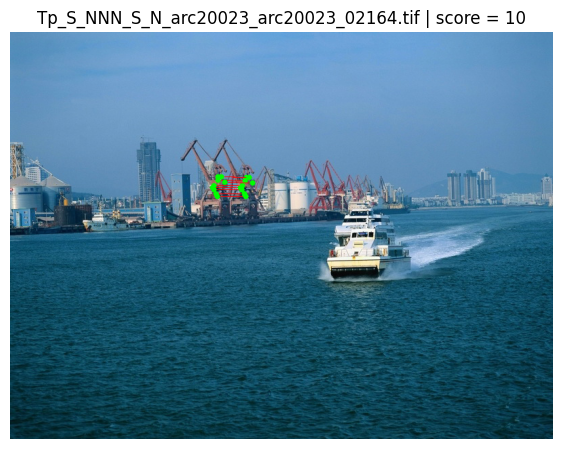

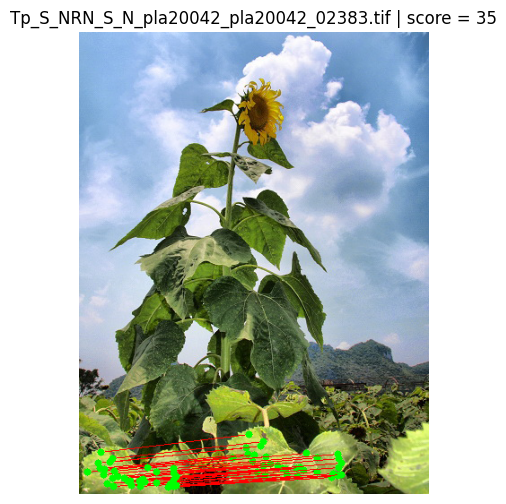

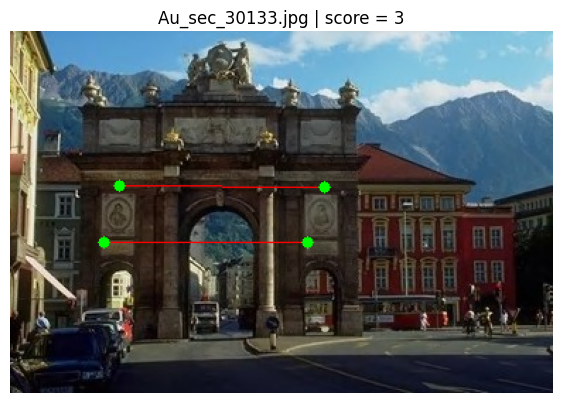

In [18]:
def show_matches(path):
    score, good = copy_move_score(path)
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    s = 800 / max(img.shape[:2])
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s)
    for p1, p2 in good:
        cv2.line(img, tuple(p1.astype(int)), tuple(p2.astype(int)), (255, 0, 0), 1)
        cv2.circle(img, tuple(p1.astype(int)), 4, (0, 255, 0), -1)
        cv2.circle(img, tuple(p2.astype(int)), 4, (0, 255, 0), -1)
    plt.figure(figsize=(7, 6)); plt.imshow(img)
    plt.title(f"{os.path.basename(path)} | score = {score}"); plt.axis("off")
    plt.show()

cm_files = [p for p in tamp if os.path.basename(p).startswith("Tp_S")]
print("Copy-move images found:", len(cm_files))

for p in random.sample(cm_files, 3):
    show_matches(p)
show_matches(random.choice(auth))   # an authentic one for comparison

In [19]:
from sklearn.metrics import classification_report, f1_score

def subset(X, y):
    items = [(p, 0 if l == 0 else 1) for p, l in zip(X, y)
             if l == 0 or os.path.basename(p).startswith("Tp_S")]
    return [p for p, _ in items], np.array([l for _, l in items])

Pv, Lv = subset(X_val, y_val)
Pt, Lt = subset(X_test, y_test)
print("Val:", len(Pv), "| Test:", len(Pt))

sv = np.array([copy_move_score(p)[0] for p in tqdm(Pv)])
st = np.array([copy_move_score(p)[0] for p in tqdm(Pt)])

best_t = max(range(0, 40), key=lambda t: f1_score(Lv, sv > t))
print("Best threshold (on validation):", best_t)

print(classification_report(Lt, st > best_t, target_names=["Authentic", "Copy-move"]))

Val: 1607 | Test: 1602


100%|██████████| 1602/1602 [02:46<00:00,  9.63it/s]


Best threshold (on validation): 3
              precision    recall  f1-score   support

   Authentic       0.84      0.90      0.87      1124
   Copy-move       0.72      0.61      0.66       478

    accuracy                           0.81      1602
   macro avg       0.78      0.75      0.77      1602
weighted avg       0.81      0.81      0.81      1602



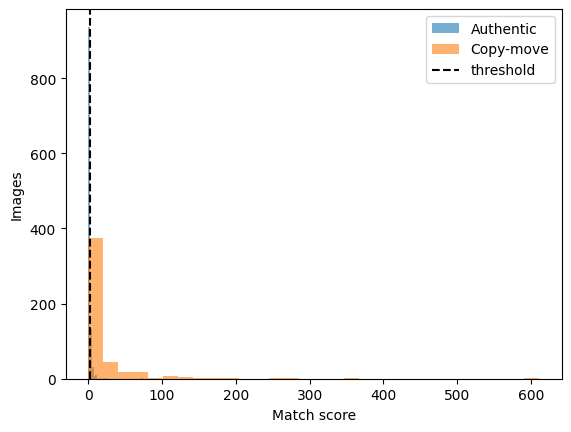

In [20]:
plt.hist(st[Lt == 0], bins=30, alpha=0.6, label="Authentic")
plt.hist(st[Lt == 1], bins=30, alpha=0.6, label="Copy-move")
plt.axvline(best_t, color="k", linestyle="--", label="threshold")
plt.xlabel("Match score"); plt.ylabel("Images"); plt.legend()
plt.show()

In [21]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

print("ROC-AUC (test):", round(roc_auc_score(Lt, st), 3))
print("thr | precision | recall | false-alarm rate on authentic")
for t in [2, 5, 8, 10, 15, 20, 30]:
    pred = st > t
    p = precision_score(Lt, pred, zero_division=0)
    r = recall_score(Lt, pred)
    fa = pred[Lt == 0].mean()
    print(f"{t:>3} |   {p:.2f}    |  {r:.2f}  |  {fa:.2f}")

ROC-AUC (test): 0.808
thr | precision | recall | false-alarm rate on authentic
  2 |   0.63    |  0.67  |  0.17
  5 |   0.84    |  0.45  |  0.04
  8 |   0.91    |  0.38  |  0.02
 10 |   0.94    |  0.34  |  0.01
 15 |   0.97    |  0.26  |  0.00
 20 |   0.98    |  0.22  |  0.00
 30 |   0.99    |  0.17  |  0.00


In [22]:
op_t = next(t for t in range(0, 60) if (sv[Lv == 0] > t).mean() <= 0.05)
print("Operating threshold:", op_t)
print(classification_report(Lt, st > op_t, target_names=["Authentic", "Copy-move"]))

Operating threshold: 4
              precision    recall  f1-score   support

   Authentic       0.82      0.95      0.88      1124
   Copy-move       0.82      0.52      0.64       478

    accuracy                           0.82      1602
   macro avg       0.82      0.74      0.76      1602
weighted avg       0.82      0.82      0.81      1602



In [23]:
COPY_MOVE_THRESHOLD = 4

## **Detector 3 is AI-generated images detection**

In [24]:
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images -p /content/cifake --unzip

for root, dirs, files in os.walk("/content/cifake"):
    print(root, "| subfolders:", dirs, "| files:", len(files))
    if root.count("/") > 4: break

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:07<00:00, 13.8MB/s]

/content/cifake | subfolders: ['test', 'train'] | files: 0
/content/cifake/test | subfolders: ['REAL', 'FAKE'] | files: 0
/content/cifake/test/REAL | subfolders: [] | files: 10000
/content/cifake/test/FAKE | subfolders: [] | files: 10000
/content/cifake/train | subfolders: ['REAL', 'FAKE'] | files: 0
/content/cifake/train/REAL | subfolders: [] | files: 50000
/content/cifake/train/FAKE | subfolders: [] | files: 50000


In [25]:
import tensorflow as tf
from tensorflow.keras import layers, models

CIFAKE = "/content/cifake"
BATCH = 128

# class_names order makes REAL = 0 and FAKE (AI) = 1
common = dict(image_size=(32, 32), batch_size=BATCH, label_mode="binary",
              class_names=["REAL", "FAKE"])

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{CIFAKE}/train", validation_split=0.1, subset="training", seed=42, **common)
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{CIFAKE}/train", validation_split=0.1, subset="validation", seed=42, **common)
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{CIFAKE}/test", shuffle=False, **common)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.prefetch(tf.data.AUTOTUNE)

Found 100000 files belonging to 2 classes.
Using 90000 files for training.
Found 100000 files belonging to 2 classes.
Using 10000 files for validation.
Found 20000 files belonging to 2 classes.


In [26]:
ai_model = models.Sequential([
    layers.Input((32, 32, 3)),
    layers.Rescaling(1/255),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
ai_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="binary_crossentropy", metrics=["accuracy"])

early = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                         restore_best_weights=True)
hist = ai_model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[early])

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 36ms/step - accuracy: 0.8974 - loss: 0.2535 - val_accuracy: 0.9011 - val_loss: 0.2363
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.9369 - loss: 0.1632 - val_accuracy: 0.8072 - val_loss: 0.4904
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.9464 - loss: 0.1400 - val_accuracy: 0.9242 - val_loss: 0.1933
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.9528 - loss: 0.1251 - val_accuracy: 0.9436 - val_loss: 0.1429
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.9557 - loss: 0.1148 - val_accuracy: 0.9394 - val_loss: 0.1522
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.9591 - loss: 0.1070 - val_accuracy: 0.9447 - val_loss: 0.1412
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.9629 - loss: 0.0974 - val_accuracy: 0.9532 - val_loss: 0.1229
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.9663 - loss: 0.0897 - 

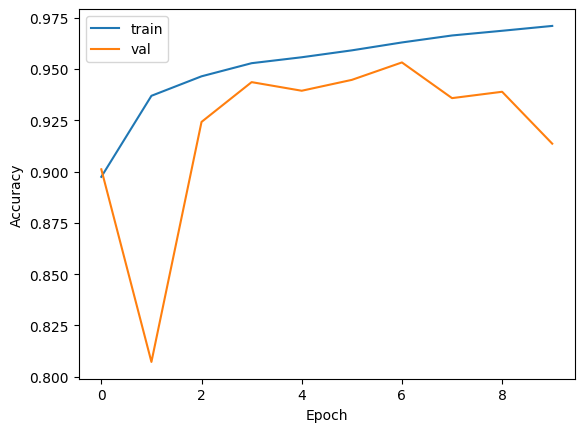

In [27]:
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.show()

157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step
              precision    recall  f1-score   support

        Real       0.95      0.96      0.95     10000
AI-generated       0.96      0.95      0.95     10000

    accuracy                           0.95     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.95      0.95      0.95     20000

ROC-AUC: 0.991


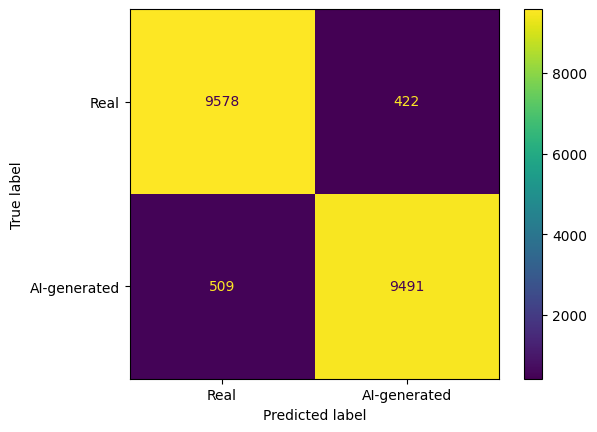

In [28]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)
y_prob = ai_model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=["Real", "AI-generated"]))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=["Real", "AI-generated"]).plot()
plt.show()

In [29]:
def ai_score(path):
    img = Image.open(path).convert("RGB").resize((32, 32), Image.BICUBIC)
    x = np.asarray(img, dtype=np.float32)[None]
    return float(ai_model.predict(x, verbose=0)[0][0])

sample = random.sample(auth, 200)
scores = np.array([ai_score(p) for p in tqdm(sample)])
print("Authentic CASIA images flagged as AI:", round((scores > 0.5).mean(), 2))
print("Mean AI score:", round(scores.mean(), 2))

100%|██████████| 200/200 [00:17<00:00, 11.23it/s]

Authentic CASIA images flagged as AI: 0.32
Mean AI score: 0.35


In [30]:
def load32(p):
    return np.asarray(Image.open(p).convert("RGB").resize((32, 32), Image.BICUBIC),
                      dtype=np.float32)

casia_tr = [p for p, l in zip(X_train, y_train) if l == 0]
casia_va = [p for p, l in zip(X_val,   y_val)   if l == 0]
casia_te = [p for p, l in zip(X_test,  y_test)  if l == 0]

Xc_tr = np.array([load32(p) for p in tqdm(casia_tr)])
Xc_va = np.array([load32(p) for p in tqdm(casia_va)])
Xc_te = np.array([load32(p) for p in tqdm(casia_te)])
print(Xc_tr.shape, Xc_va.shape, Xc_te.shape)

100%|██████████| 1124/1124 [00:02<00:00, 474.59it/s]

(5243, 32, 32, 3) (1124, 32, 32, 3) (1124, 32, 32, 3)


In [31]:
def make_ds(X, repeat=1):
    y = np.zeros((len(X), 1), dtype="float32")     # 0 = real
    return tf.data.Dataset.from_tensor_slices((X, y)).repeat(repeat)

mixed_train = (train_ds.unbatch()
               .concatenate(make_ds(Xc_tr, repeat=3))   # repeat 3x so CASIA isn't drowned out
               .shuffle(20000, seed=42).batch(BATCH).prefetch(tf.data.AUTOTUNE))
mixed_val = (val_ds.unbatch()
             .concatenate(make_ds(Xc_va))
             .batch(BATCH).prefetch(tf.data.AUTOTUNE))

ai_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                 loss="binary_crossentropy", metrics=["accuracy"])
hist2 = ai_model.fit(mixed_train, validation_data=mixed_val, epochs=8, callbacks=[early])

Epoch 1/8
    827/Unknown 29s 25ms/step - accuracy: 0.9683 - loss: 0.0819

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


827/827 ━━━━━━━━━━━━━━━━━━━━ 32s 29ms/step - accuracy: 0.9633 - loss: 0.0965 - val_accuracy: 0.9201 - val_loss: 0.2097
Epoch 2/8
827/827 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9667 - loss: 0.0897 - val_accuracy: 0.9385 - val_loss: 0.1623
Epoch 3/8
827/827 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9700 - loss: 0.0806 - val_accuracy: 0.9393 - val_loss: 0.1612


In [32]:
p_casia = ai_model.predict(Xc_te, verbose=0).ravel()
print("Unseen CASIA authentic flagged as AI:", round((p_casia > 0.5).mean(), 2))

y_prob = ai_model.predict(test_ds).ravel()
print("CIFAKE test accuracy:", round(((y_prob > 0.5).astype(int) == y_true).mean(), 3))

Unseen CASIA authentic flagged as AI: 0.03
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step
CIFAKE test accuracy: 0.919


In [33]:
from google.colab import drive
drive.mount('/content/drive')

os.makedirs("/content/drive/MyDrive/forgery", exist_ok=True)
model.save("/content/drive/MyDrive/forgery/splicing_model.keras")
ai_model.save("/content/drive/MyDrive/forgery/ai_model.keras")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **fusion between the three detectors**

In [34]:
SPLICE_T = 0.5
COPY_MOVE_THRESHOLD = 4
AI_T = 0.5

def classify(path):
    p_splice = float(model.predict(ela(path)[None], verbose=0)[0][0])
    n_copy, _ = copy_move_score(path)
    p_ai = ai_score(path)

    flagged = []
    if p_splice > SPLICE_T:           flagged.append("Splicing")
    if n_copy > COPY_MOVE_THRESHOLD:  flagged.append("Copy-move")
    if p_ai > AI_T:                   flagged.append("AI-generated")

    verdict = "Potentially Forged" if flagged else "Authentic"
    scores = {"splicing": round(p_splice, 2),
              "copy_move_matches": n_copy,
              "ai": round(p_ai, 2)}
    return verdict, flagged, scores

In [35]:
splice_files = [p for p in tamp if os.path.basename(p).startswith("Tp_D")]
tests = random.sample(auth, 2) + random.sample(cm_files, 2) + random.sample(splice_files, 2)

for p in tests:
    print(os.path.basename(p), "->", classify(p))

Au_arc_30063.jpg -> ('Authentic', [], {'splicing': 0.0, 'copy_move_matches': 2, 'ai': 0.02})
Au_arc_30027.jpg -> ('Authentic', [], {'splicing': 0.0, 'copy_move_matches': 3, 'ai': 0.0})
Tp_S_NNN_S_O_art10004_art10004_20042.jpg -> ('Potentially Forged', ['Splicing'], {'splicing': 0.92, 'copy_move_matches': 2, 'ai': 0.07})
Tp_S_NNN_S_N_nat20100_nat20100_01604.tif -> ('Potentially Forged', ['Splicing', 'Copy-move'], {'splicing': 0.73, 'copy_move_matches': 71, 'ai': 0.01})
Tp_D_NNN_S_N_pla00088_ani00100_00610.tif -> ('Potentially Forged', ['Splicing'], {'splicing': 1.0, 'copy_move_matches': 0, 'ai': 0.09})
Tp_D_CRN_M_N_art00067_ani00095_11803.jpg -> ('Potentially Forged', ['Splicing'], {'splicing': 0.96, 'copy_move_matches': 2, 'ai': 0.08})


100%|██████████| 600/600 [02:44<00:00,  3.64it/s]


              precision    recall  f1-score   support

   Authentic       0.97      0.83      0.89       367
      Forged       0.78      0.96      0.86       233

    accuracy                           0.88       600
   macro avg       0.87      0.89      0.88       600
weighted avg       0.90      0.88      0.88       600



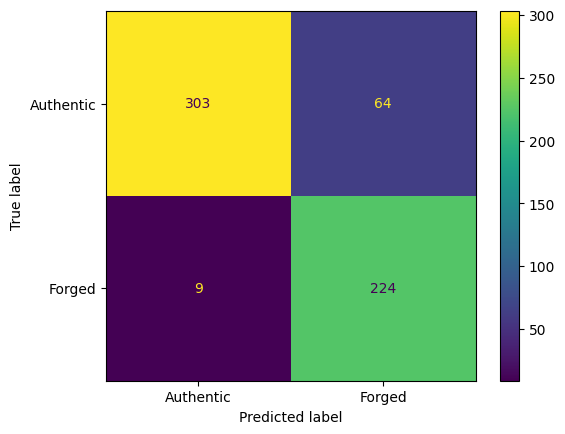

In [36]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

random.seed(0)
idx = random.sample(range(len(X_test)), 600)     # 600 images to keep it quick (~3-5 min)
P = [X_test[i] for i in idx]
L = np.array([y_test[i] for i in idx])

pred = []
for p in tqdm(P):
    verdict, _, _ = classify(p)
    pred.append(int(verdict == "Potentially Forged"))
pred = np.array(pred)

print(classification_report(L, pred, target_names=["Authentic", "Forged"]))
ConfusionMatrixDisplay(confusion_matrix(L, pred),
                       display_labels=["Authentic", "Forged"]).plot()
plt.show()

# **Compute and store all three scores per image**

In [37]:
def get_scores(paths):
    out = []
    for p in tqdm(paths):
        s = float(model.predict(ela(p)[None], verbose=0)[0][0])
        c, _ = copy_move_score(p)
        a = ai_score(p)
        out.append((s, c, a))
    return np.array(out)

random.seed(1)
vidx = random.sample(range(len(X_val)), 600)
Pv2 = [X_val[i] for i in vidx]
Lv2 = np.array([y_val[i] for i in vidx])

Sv = get_scores(Pv2)    # validation scores, used for tuning
St = get_scores(P)      # test scores (P and L come from Cell 30)

100%|██████████| 600/600 [02:43<00:00,  3.66it/s]


In [38]:
import itertools

# 1) false-alarm rate of each detector on AUTHENTIC validation images
auth_v = Sv[Lv2 == 0]
print("False alarms on authentic -> splicing:", round((auth_v[:, 0] > 0.5).mean(), 2),
      "| copy-move:", round((auth_v[:, 1] > 4).mean(), 2),
      "| AI:", round((auth_v[:, 2] > 0.5).mean(), 2))

# 2) sweep thresholds, pick the best balanced accuracy on VALIDATION
def predict(S, st, ct, at):
    return ((S[:, 0] > st) | (S[:, 1] > ct) | (S[:, 2] > at)).astype(int)

rows = []
for st, ct, at in itertools.product([0.5, 0.6, 0.7, 0.8, 0.9], [4, 6, 8, 12], [0.5, 0.7, 0.9]):
    pr = predict(Sv, st, ct, at)
    recall_f = (pr[Lv2 == 1] == 1).mean()
    fa = (pr[Lv2 == 0] == 1).mean()
    rows.append(((recall_f + (1 - fa)) / 2, recall_f, fa, st, ct, at))

rows.sort(reverse=True)
print("\nbal.acc | forged recall | false alarms | splice_t | copy_t | ai_t")
for r in rows[:5]:
    print(f"{r[0]:.3f}   |    {r[1]:.2f}       |    {r[2]:.2f}      |   {r[3]}    |  {r[4]}   | {r[5]}")

# 3) apply the best setting to the TEST sample
_, _, _, SPLICE_T, COPY_MOVE_THRESHOLD, AI_T = rows[0]
pred = predict(St, SPLICE_T, COPY_MOVE_THRESHOLD, AI_T)
print("\nChosen:", SPLICE_T, COPY_MOVE_THRESHOLD, AI_T)
print(classification_report(L, pred, target_names=["Authentic", "Forged"]))

False alarms on authentic -> splicing: 0.13 | copy-move: 0.05 | AI: 0.05

bal.acc | forged recall | false alarms | splice_t | copy_t | ai_t
0.889   |    0.92       |    0.15      |   0.5    |  12   | 0.9
0.887   |    0.93       |    0.15      |   0.5    |  8   | 0.9
0.887   |    0.89       |    0.12      |   0.7    |  12   | 0.9
0.886   |    0.91       |    0.14      |   0.6    |  12   | 0.9
0.886   |    0.93       |    0.16      |   0.5    |  12   | 0.7

Chosen: 0.5 12 0.9
              precision    recall  f1-score   support

   Authentic       0.96      0.89      0.92       367
      Forged       0.84      0.95      0.89       233

    accuracy                           0.91       600
   macro avg       0.90      0.92      0.91       600
weighted avg       0.92      0.91      0.91       600



In [39]:
y_prob = ai_model.predict(test_ds, verbose=0).ravel()
for t in [0.5, 0.9]:
    pred_ai = (y_prob > t).astype(int)
    print(f"AI threshold {t}: AI images caught = {pred_ai[y_true == 1].mean():.2f} | "
          f"CIFAKE real wrongly flagged = {pred_ai[y_true == 0].mean():.2f}")

AI threshold 0.5: AI images caught = 0.85 | CIFAKE real wrongly flagged = 0.01
AI threshold 0.9: AI images caught = 0.63 | CIFAKE real wrongly flagged = 0.00


In [40]:
p_casia = ai_model.predict(Xc_te, verbose=0).ravel()   # unseen CASIA authentic images

print("thr | AI caught | CIFAKE real flagged | CASIA authentic flagged")
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pr = (y_prob > t).astype(int)
    print(f"{t}  |   {pr[y_true == 1].mean():.2f}    |       {pr[y_true == 0].mean():.2f}          |        {(p_casia > t).mean():.2f}")

thr | AI caught | CIFAKE real flagged | CASIA authentic flagged
0.5  |   0.85    |       0.01          |        0.03
0.6  |   0.82    |       0.01          |        0.02
0.7  |   0.79    |       0.01          |        0.02
0.8  |   0.73    |       0.00          |        0.01
0.9  |   0.63    |       0.00          |        0.01


In [41]:
import json
config = {"splice_t": float(SPLICE_T), "copy_move_t": int(COPY_MOVE_THRESHOLD), "ai_t": float(AI_T)}
with open("/content/drive/MyDrive/forgery/config.json", "w") as f:
    json.dump(config, f)
print(config)

{'splice_t': 0.5, 'copy_move_t': 12, 'ai_t': 0.9}


In [42]:
AI_T = 0.7   # replace with the value you chose

pred = predict(St, SPLICE_T, COPY_MOVE_THRESHOLD, AI_T)
print(classification_report(L, pred, target_names=["Authentic", "Forged"]))

# save the final settings
config = {"splice_t": float(SPLICE_T), "copy_move_t": int(COPY_MOVE_THRESHOLD), "ai_t": float(AI_T)}
with open("/content/drive/MyDrive/forgery/config.json", "w") as f:
    json.dump(config, f)
print(config)

              precision    recall  f1-score   support

   Authentic       0.96      0.87      0.91       367
      Forged       0.82      0.95      0.88       233

    accuracy                           0.90       600
   macro avg       0.89      0.91      0.90       600
weighted avg       0.91      0.90      0.90       600

{'splice_t': 0.5, 'copy_move_t': 12, 'ai_t': 0.7}


In [43]:
def ela_heatmap(path, quality=90):
    img = Image.open(path).convert("RGB")
    buf = io.BytesIO(); img.save(buf, "JPEG", quality=quality); buf.seek(0)
    resaved = Image.open(buf).convert("RGB")
    diff = np.abs(np.asarray(img, dtype=np.int16) - np.asarray(resaved, dtype=np.int16)).sum(axis=2)
    diff = cv2.GaussianBlur(diff.astype(np.float32), (0, 0), 3)   # smooth for readability
    return img, diff

def explain(path):
    verdict, flagged, scores = classify(path)
    orig, diff = ela_heatmap(path)

    # copy-move evidence: draw the matched pairs on the (resized) image
    n, good = copy_move_score(path)
    cm = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    s = 800 / max(cm.shape[:2])
    if s < 1:
        cm = cv2.resize(cm, None, fx=s, fy=s)
    for p1, p2 in good:
        cv2.line(cm, tuple(p1.astype(int)), tuple(p2.astype(int)), (255, 0, 0), 1)
        cv2.circle(cm, tuple(p1.astype(int)), 4, (0, 255, 0), -1)
        cv2.circle(cm, tuple(p2.astype(int)), 4, (0, 255, 0), -1)

    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(orig); ax[0].set_title("Original")
    ax[1].imshow(diff, cmap="jet", vmax=np.percentile(diff, 99)); ax[1].set_title("ELA heatmap (splicing evidence)")
    ax[2].imshow(cm); ax[2].set_title(f"Copy-move matches: {n}")
    for a in ax: a.axis("off")
    plt.suptitle(f"{verdict} | flagged: {flagged if flagged else 'none'} | {scores}", fontsize=11)
    plt.show()

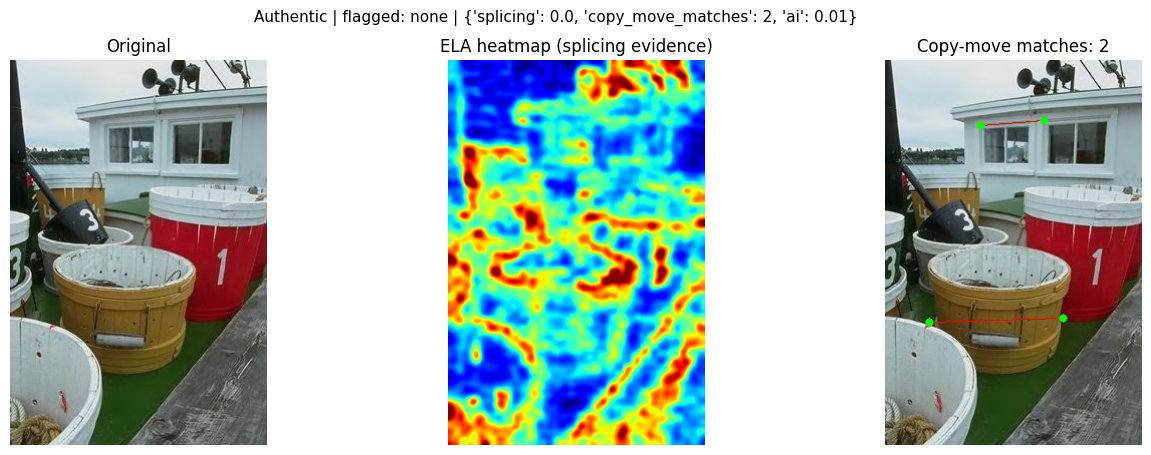

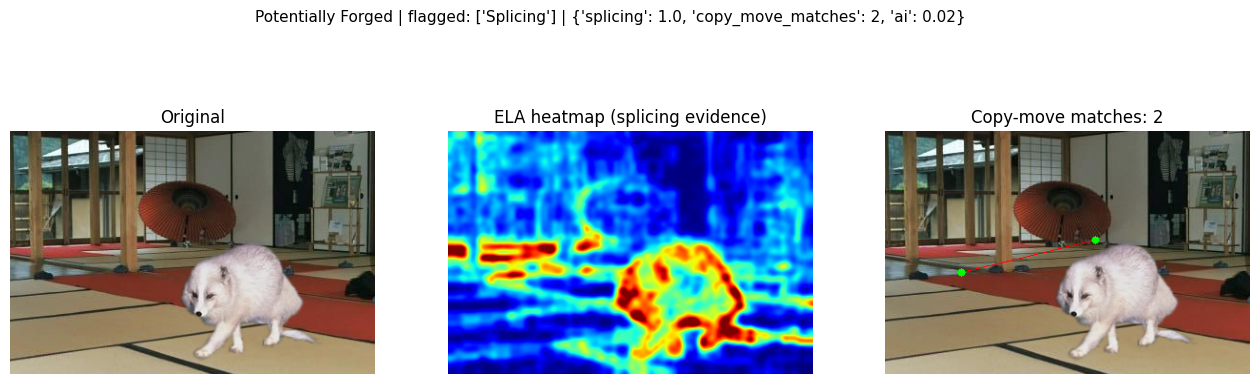

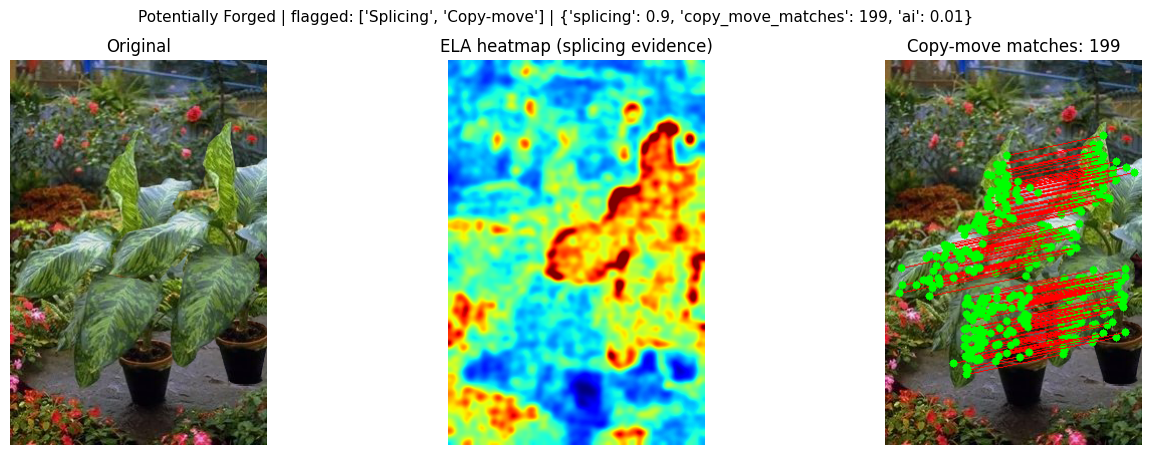

In [44]:
explain(random.choice(auth))
explain(random.choice(splice_files))
explain(random.choice(cm_files))

fixing the limitation I flagged earlier. The detector was trained on CIFAKE, which has only tiny 32×32 images from one older generator (Stable Diffusion 1.4). Modern generators (Midjourney, DALL·E 3, newer Stable Diffusion) make different artifacts, and shrinking a full-size image to 32×32 erases most of the fine detail that gives AI images away. That’s why 94% on CIFAKE didn’t carry over to your images.

In [45]:
!pip install -q datasets
from datasets import load_dataset

ds = load_dataset("julienlucas/midjourney-dalle-sd-nanobananapro-dataset")
print(ds)

names = ds["train"].features["label"].names
print(names)                       # which number is "fake"?
FAKE_ID = names.index("fake")

# check the balance, and cap the size if it's large (faster to process)
import collections
print(collections.Counter(ds["train"]["label"]))
if len(ds["train"]) > 8000:
    ds["train"] = ds["train"].shuffle(seed=42).select(range(8000))

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 10695
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 2000
    })
})
['fake', 'real']
Counter({1: 5500, 0: 5195})


In [46]:
SIZE = 224

def to_arrays(split):
    X, y = [], []
    for ex in tqdm(split):
        img = ex["image"].convert("RGB").resize((SIZE, SIZE), Image.BICUBIC)
        X.append(np.asarray(img, dtype=np.uint8))
        y.append(1 if ex["label"] == FAKE_ID else 0)
    return np.array(X), np.array(y)

def load224(p):
    return np.asarray(Image.open(p).convert("RGB").resize((SIZE, SIZE), Image.BICUBIC), dtype=np.uint8)

Xa, ya = to_arrays(ds["train"])
Xt, yt = to_arrays(ds["test"])

random.seed(3)
casia_real_tr = random.sample(casia_tr, 1500)      # from Cell 24
casia_real_te = random.sample(casia_te, 300)
Xc2 = np.array([load224(p) for p in tqdm(casia_real_tr)])
Xc2_te = np.array([load224(p) for p in tqdm(casia_real_te)])

X_all = np.concatenate([Xa, Xc2]); y_all = np.concatenate([ya, np.zeros(len(Xc2), int)])
X_tr2, X_va2, y_tr2, y_va2 = train_test_split(X_all, y_all, test_size=0.1, stratify=y_all, random_state=42)
print(X_tr2.shape, X_va2.shape, Xt.shape, "| fake share:", y_all.mean().round(2))

  0%|          | 28/8000 [00:01<07:34, 17.54it/s]/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
100%|██████████| 300/300 [00:00<00:00, 319.41it/s]


(8550, 224, 224, 3) (950, 224, 224, 3) (2000, 224, 224, 3) | fake share: 0.41


In [47]:
from tensorflow.keras.applications import EfficientNetB0

base = EfficientNetB0(include_top=False, weights="imagenet",
                      input_shape=(224, 224, 3), pooling="avg")
base.trainable = False

inp = layers.Input((224, 224, 3))
x = layers.RandomFlip("horizontal")(inp)
x = base(x, training=False)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1, activation="sigmoid")(x)
ai_v2 = models.Model(inp, out)

ai_v2.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
h1 = ai_v2.fit(X_tr2, y_tr2, validation_data=(X_va2, y_va2), epochs=5, batch_size=32)

# fine-tune the pretrained part gently
base.trainable = True
ai_v2.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="binary_crossentropy", metrics=["accuracy"])
h2 = ai_v2.fit(X_tr2, y_tr2, validation_data=(X_va2, y_va2), epochs=5, batch_size=32)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 76s 144ms/step - accuracy: 0.7294 - loss: 0.5360 - val_accuracy: 0.7979 - val_loss: 0.4575
Epoch 2/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.7883 - loss: 0.4466 - val_accuracy: 0.8179 - val_loss: 0.4287
Epoch 3/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8053 - loss: 0.4231 - val_accuracy: 0.8263 - val_loss: 0.4123
Epoch 4/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8171 - loss: 0.4097 - val_accuracy: 0.8200 - val_loss: 0.4054
Epoch 5/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.8138 - loss: 0.4018 - val_accuracy: 0.8379 - val_loss: 0.3994
Epoch 1/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 192s 366ms/step - accuracy: 0.7833 - loss: 0.4513 - val_accuracy: 0.8221 - val_loss: 0.4031
Epoch 2/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 32s 120ms/step - accuracy: 0.8225 - loss: 0.4008 - val_accuracy: 0.8305 - val_loss: 0.3790
Epoch 3/5
268/268 ━━━━━━━━━━━━━━━━━━━━ 32s 119

In [48]:
from sklearn.metrics import classification_report, roc_auc_score

pt = ai_v2.predict(Xt, verbose=0).ravel()
print(classification_report(yt, pt > 0.5, target_names=["Real", "AI-generated"]))
print("ROC-AUC:", round(roc_auc_score(yt, pt), 3))

pc = ai_v2.predict(Xc2_te, verbose=0).ravel()
print("Unseen CASIA authentic flagged as AI:", round((pc > 0.5).mean(), 2))

print("thr | AI caught | real (dataset) flagged | CASIA authentic flagged")
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    print(f"{t}  |  {(pt[yt == 1] > t).mean():.2f}   |   {(pt[yt == 0] > t).mean():.2f}   |   {(pc > t).mean():.2f}")

              precision    recall  f1-score   support

        Real       0.78      0.93      0.85      1000
AI-generated       0.91      0.74      0.81      1000

    accuracy                           0.83      2000
   macro avg       0.85      0.83      0.83      2000
weighted avg       0.85      0.83      0.83      2000

ROC-AUC: 0.922
Unseen CASIA authentic flagged as AI: 0.05
thr | AI caught | real (dataset) flagged | CASIA authentic flagged
0.5  |  0.74   |   0.07   |   0.05
0.6  |  0.66   |   0.04   |   0.02
0.7  |  0.58   |   0.03   |   0.01
0.8  |  0.48   |   0.02   |   0.00
0.9  |  0.34   |   0.01   |   0.00


In [52]:
def ai_score(img):
    x = np.asarray(img.convert("RGB").resize((224, 224), Image.BICUBIC), dtype=np.float32)[None]
    return float(ai_model.predict(x, verbose=0)[0][0])

In [53]:
from sklearn.metrics import roc_auc_score
from google.colab import drive
drive.mount('/content/drive')

for t in [0.3, 0.4, 0.5]:
    print(f"{t} | AI caught {(pt[yt == 1] > t).mean():.2f} | "
          f"dataset real flagged {(pt[yt == 0] > t).mean():.2f} | "
          f"CASIA authentic flagged {(pc > t).mean():.2f}")

# the OLD CIFAKE detector on the same modern test images (shrunk to 32x32)
old = tf.keras.models.load_model("/content/drive/MyDrive/forgery/ai_model.keras")
Xt32 = np.array([cv2.resize(x, (32, 32), interpolation=cv2.INTER_AREA) for x in Xt]).astype("float32")
po = old.predict(Xt32, verbose=0).ravel()
print("OLD detector ROC-AUC on modern images:", round(roc_auc_score(yt, po), 3))
print("OLD detector AI caught at 0.5:", round((po[yt == 1] > 0.5).mean(), 2),
      "| at 0.7:", round((po[yt == 1] > 0.7).mean(), 2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
0.3 | AI caught 0.86 | dataset real flagged 0.18 | CASIA authentic flagged 0.12
0.4 | AI caught 0.80 | dataset real flagged 0.12 | CASIA authentic flagged 0.07
0.5 | AI caught 0.74 | dataset real flagged 0.07 | CASIA authentic flagged 0.05
OLD detector ROC-AUC on modern images: 0.514
OLD detector AI caught at 0.5: 0.05 | at 0.7: 0.02


In [55]:
import json
AI_T2 = 0.5

ai_v2.save("/content/drive/MyDrive/forgery/ai_model_v2.keras")

cfg_path = "/content/drive/MyDrive/forgery/config.json"
cfg = json.load(open(cfg_path))
cfg["ai_t"] = AI_T2
json.dump(cfg, open(cfg_path, "w"))
print(cfg)

{'splice_t': 0.5, 'copy_move_t': 12, 'ai_t': 0.5}
